# DCCM Comparison: MUC2 Glycans vs No Glycans

- Individual DCCM heatmaps with ticks every 100 residues
- Comparative heatmaps normalized to the same scale


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

output_dir = "/home/computer2/analysis_simulations/analysis/pca_plots"
os.makedirs(output_dir, exist_ok=True)
print("Output dir:", output_dir)

Output dir: /home/computer2/analysis_simulations/analysis/pca_plots


## Load DCCM Matrices

In [2]:
dccm_nog = np.loadtxt(
    "/home/computer2/analysis_simulations/analysis/muc2_noglyc_pca_dccm/muc2_combined_noglyc_dccm.txt")
dccm_gly = np.loadtxt(
    "/home/computer2/analysis_simulations/analysis/muc2_normal_pca_dccm/muc2_normal_combined_dccm.txt")

print(f"No Glycans DCCM shape: {dccm_nog.shape}")
print(f"Glycans    DCCM shape: {dccm_gly.shape}")
print(f"No Glycans - min: {dccm_nog.min():.3f}  max: {dccm_nog.max():.3f}")
print(f"Glycans    - min: {dccm_gly.min():.3f}  max: {dccm_gly.max():.3f}")

# Global min/max for shared normalisation
vmin = min(dccm_nog.min(), dccm_gly.min())
vmax = max(dccm_nog.max(), dccm_gly.max())
print(f"\nShared colour scale: vmin={vmin:.3f}  vmax={vmax:.3f}")

No Glycans DCCM shape: (2265, 2265)
Glycans    DCCM shape: (2265, 2265)
No Glycans - min: -0.603  max: 1.000
Glycans    - min: -0.726  max: 1.000

Shared colour scale: vmin=-0.726  vmax=1.000


## Individual DCCM Heatmaps

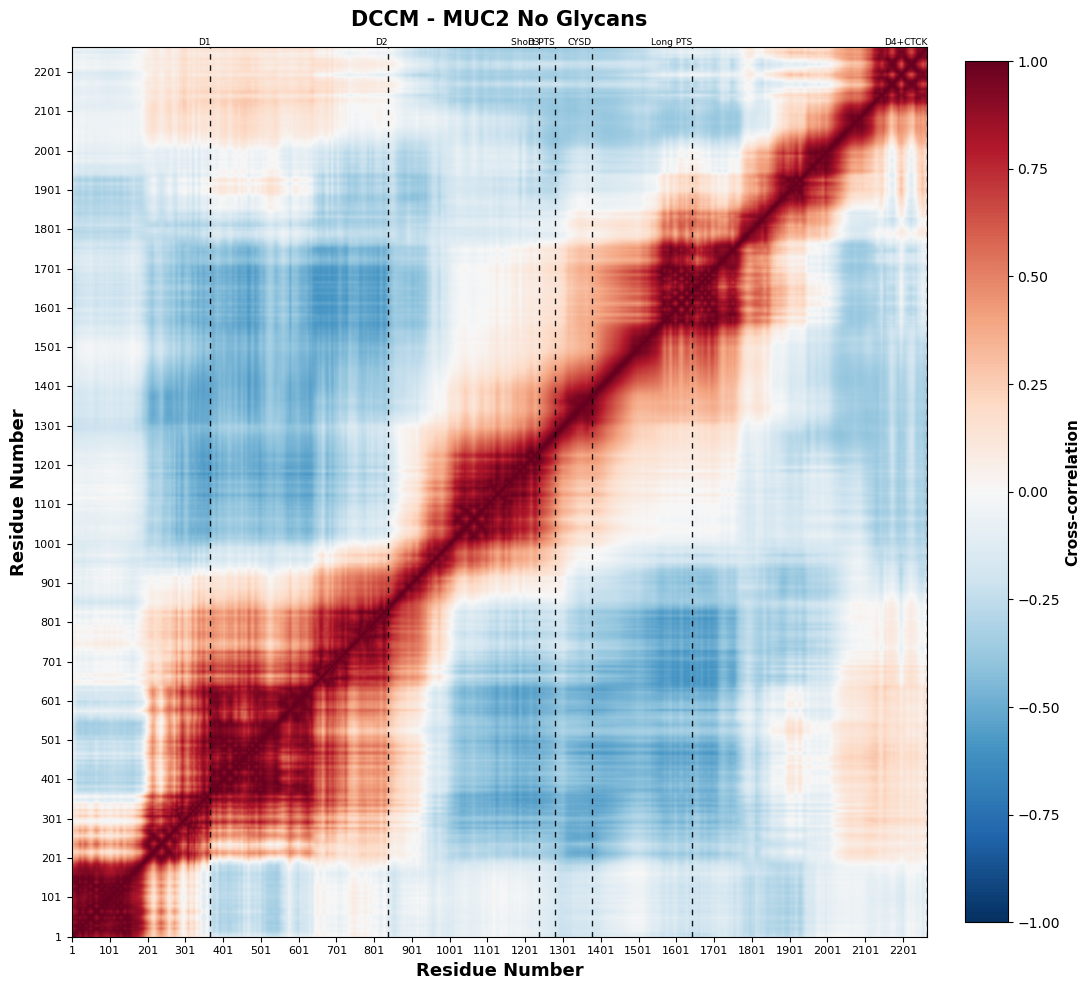

Saved: /home/computer2/analysis_simulations/analysis/pca_plots/dccm_noglycans.png


In [3]:
n = dccm_nog.shape[0]
tick_spacing = 100
ticks = np.arange(0, n, tick_spacing)
tick_labels = [str(t + 1) for t in ticks]

# Domain end boundaries (0-indexed)
domains = [
    (366,  "D1"),
    (836,  "D2"),
    (1237, "D3"),
    (1277, "Short PTS"),
    (1375, "CYSD"),
    (1641, "Long PTS"),
    (2264, "D4+CTCK"),
]

def add_domain_lines(ax):
    for end, name in domains:
        ax.axvline(end + 0.5, color="black", linewidth=1.0, linestyle=(0, (4, 4)), alpha=0.9)
        ax.text(end + 0.5, 1.01, name, ha="right", va="top",
                fontsize=6.5, color="black", rotation=0,
                transform=ax.get_xaxis_transform(), clip_on=False)

fig, ax = plt.subplots(figsize=(11, 10), dpi=100)
im = ax.imshow(dccm_nog, cmap="RdBu_r", vmin=-1, vmax=1,
               origin="lower", aspect="auto")
add_domain_lines(ax)
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Cross-correlation", fontsize=11, fontweight="bold")
cbar.ax.tick_params(labelsize=10)
ax.set_xticks(ticks)
ax.set_xticklabels(tick_labels, rotation=0, fontsize=8)
ax.set_yticks(ticks)
ax.set_yticklabels(tick_labels, fontsize=8)
ax.set_xlabel("Residue Number", fontsize=13, fontweight="bold")
ax.set_ylabel("Residue Number", fontsize=13, fontweight="bold")
ax.set_title("DCCM - MUC2 No Glycans", fontsize=15, fontweight="bold", pad=15)
plt.tight_layout()
out = os.path.join(output_dir, "dccm_noglycans.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

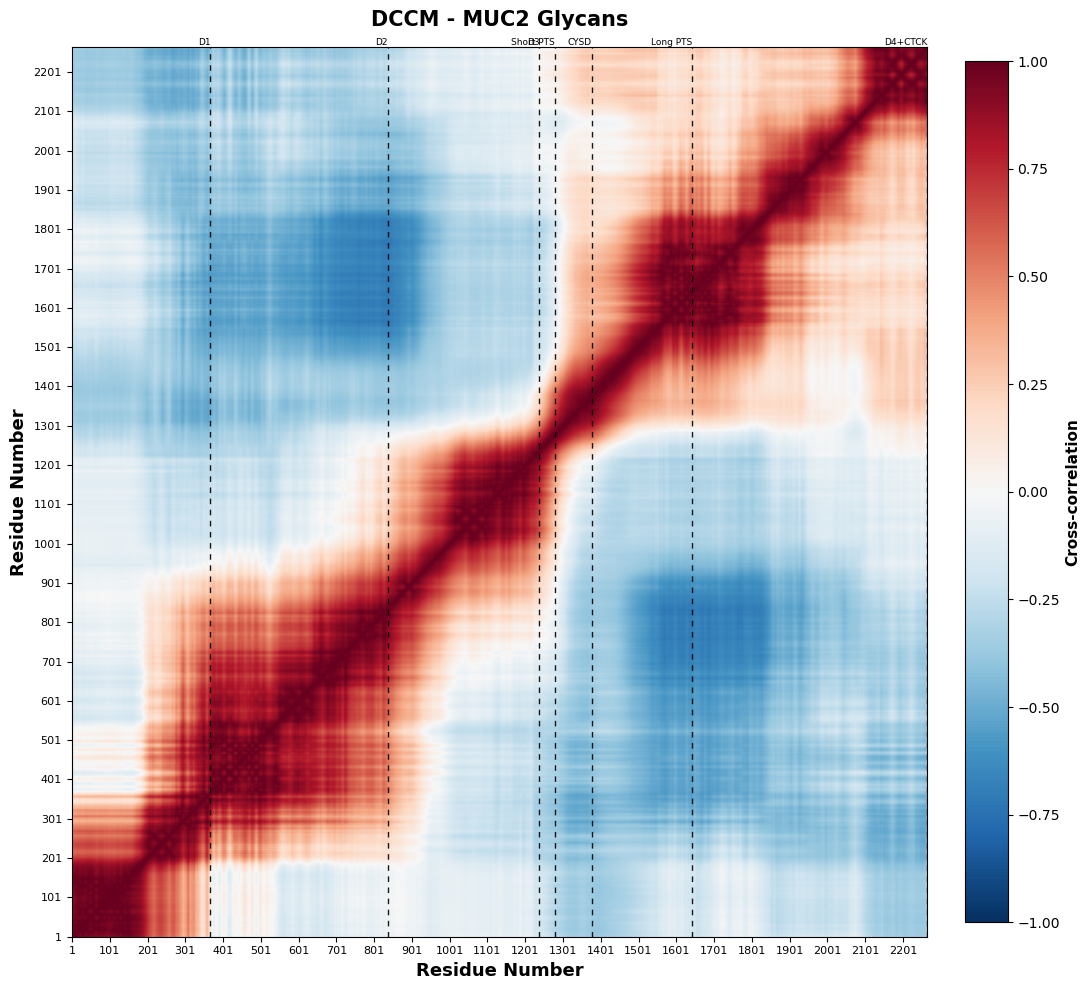

Saved: /home/computer2/analysis_simulations/analysis/pca_plots/dccm_glycans.png


In [4]:
n = dccm_gly.shape[0]
ticks = np.arange(0, n, tick_spacing)
tick_labels = [str(t + 1) for t in ticks]

fig, ax = plt.subplots(figsize=(11, 10), dpi=100)
im = ax.imshow(dccm_gly, cmap="RdBu_r", vmin=-1, vmax=1,
               origin="lower", aspect="auto")
add_domain_lines(ax)
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Cross-correlation", fontsize=11, fontweight="bold")
cbar.ax.tick_params(labelsize=10)
ax.set_xticks(ticks)
ax.set_xticklabels(tick_labels, rotation=0, fontsize=8)
ax.set_yticks(ticks)
ax.set_yticklabels(tick_labels, fontsize=8)
ax.set_xlabel("Residue Number", fontsize=13, fontweight="bold")
ax.set_ylabel("Residue Number", fontsize=13, fontweight="bold")
ax.set_title("DCCM - MUC2 Glycans", fontsize=15, fontweight="bold", pad=15)
plt.tight_layout()
out = os.path.join(output_dir, "dccm_glycans.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Comparative DCCM - Same Colour Scale

Both matrices normalised to the global min/max so differences are directly comparable.

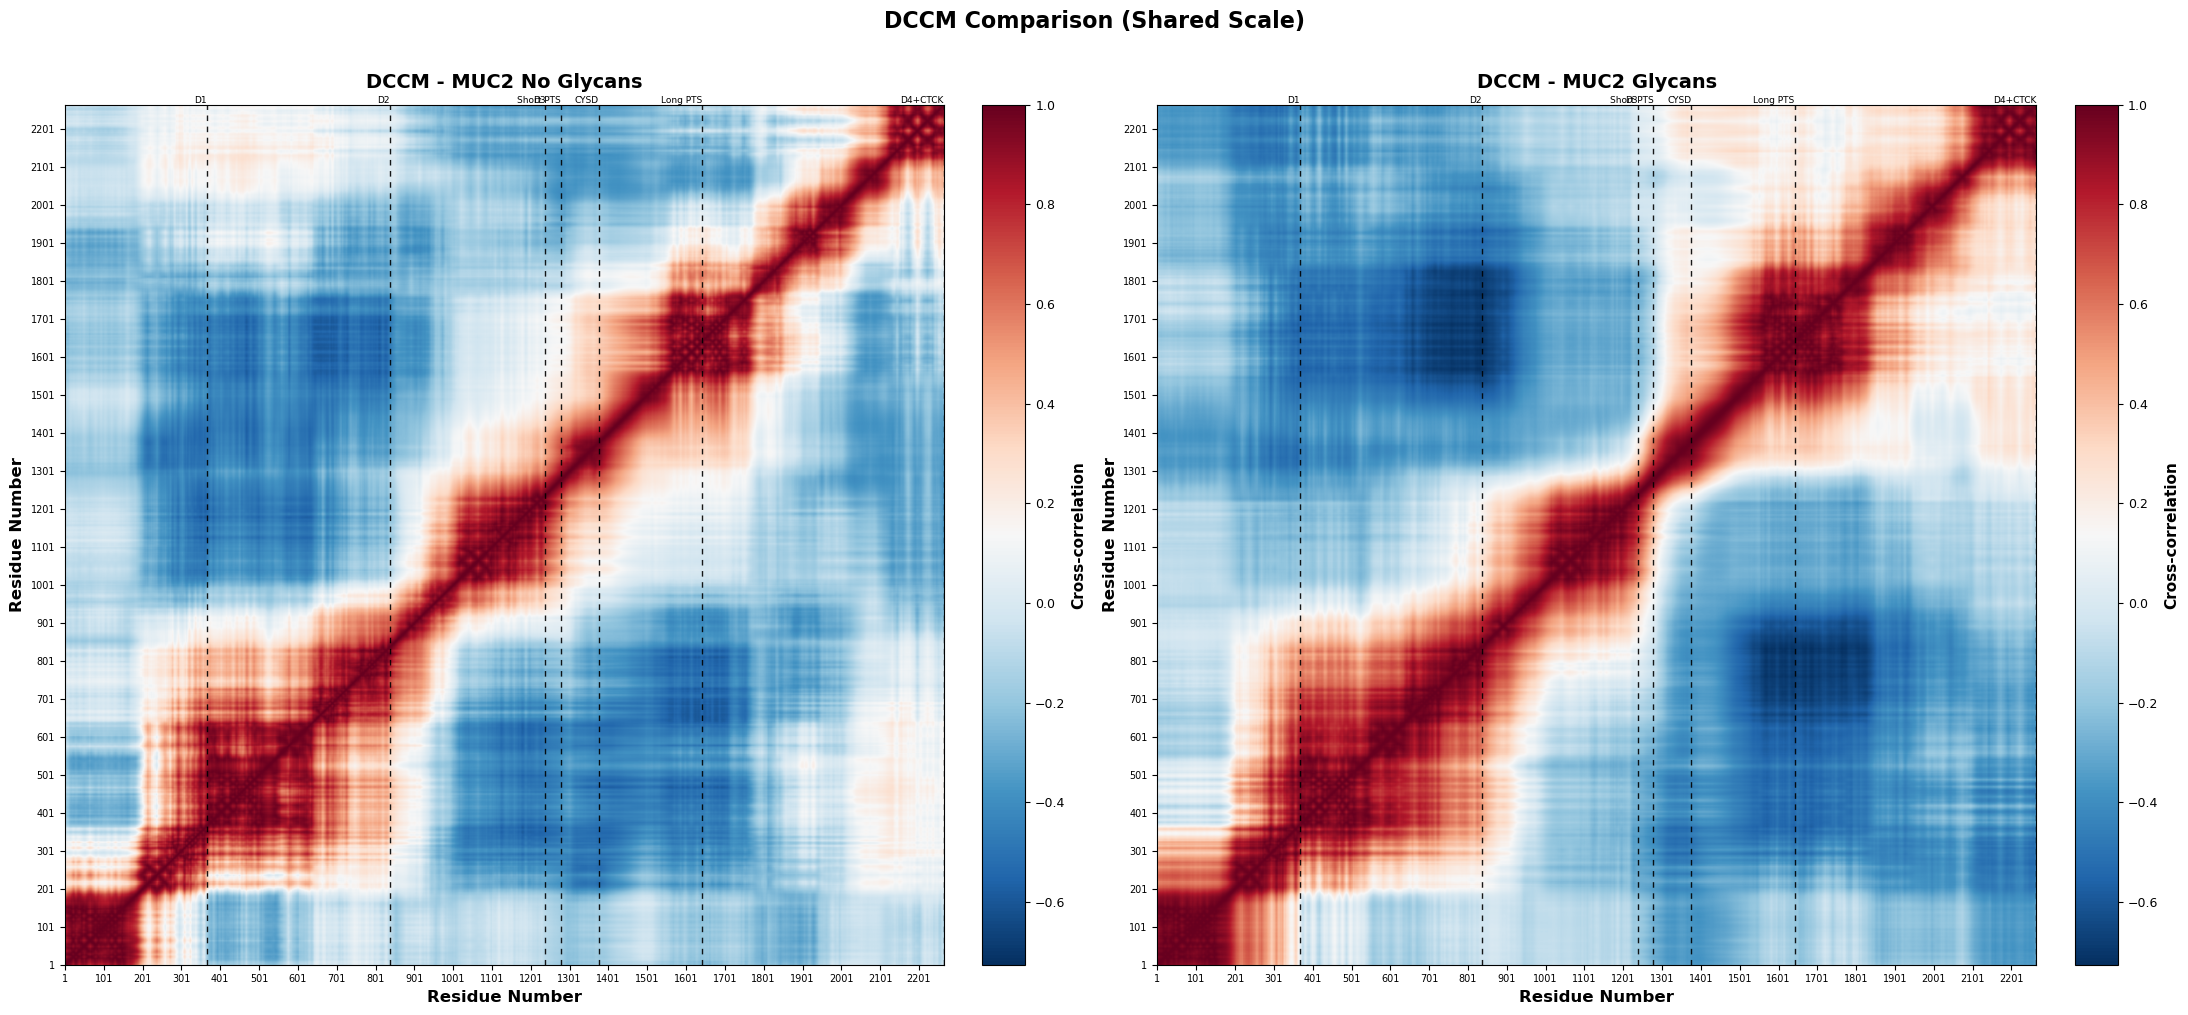

Saved: /home/computer2/analysis_simulations/analysis/pca_plots/dccm_comparison_shared_scale.png


In [5]:
n = dccm_nog.shape[0]
ticks = np.arange(0, n, tick_spacing)
tick_labels = [str(t + 1) for t in ticks]

fig, axes = plt.subplots(1, 2, figsize=(22, 10), dpi=100)

for ax, matrix, title in zip(axes,
                              [dccm_nog, dccm_gly],
                              ["No Glycans", "Glycans"]):
    im = ax.imshow(matrix, cmap="RdBu_r", vmin=vmin, vmax=vmax,
                   origin="lower", aspect="auto")
    add_domain_lines(ax)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Cross-correlation", fontsize=11, fontweight="bold")
    cbar.ax.tick_params(labelsize=9)
    ax.set_xticks(ticks)
    ax.set_xticklabels(tick_labels, rotation=0, fontsize=7)
    ax.set_yticks(ticks)
    ax.set_yticklabels(tick_labels, fontsize=7)
    ax.set_xlabel("Residue Number", fontsize=12, fontweight="bold")
    ax.set_ylabel("Residue Number", fontsize=12, fontweight="bold")
    ax.set_title(f"DCCM - MUC2 {title}", fontsize=14, fontweight="bold", pad=12)

fig.suptitle("DCCM Comparison (Shared Scale)", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
out = os.path.join(output_dir, "dccm_comparison_shared_scale.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Difference Map (Glycans - No Glycans)

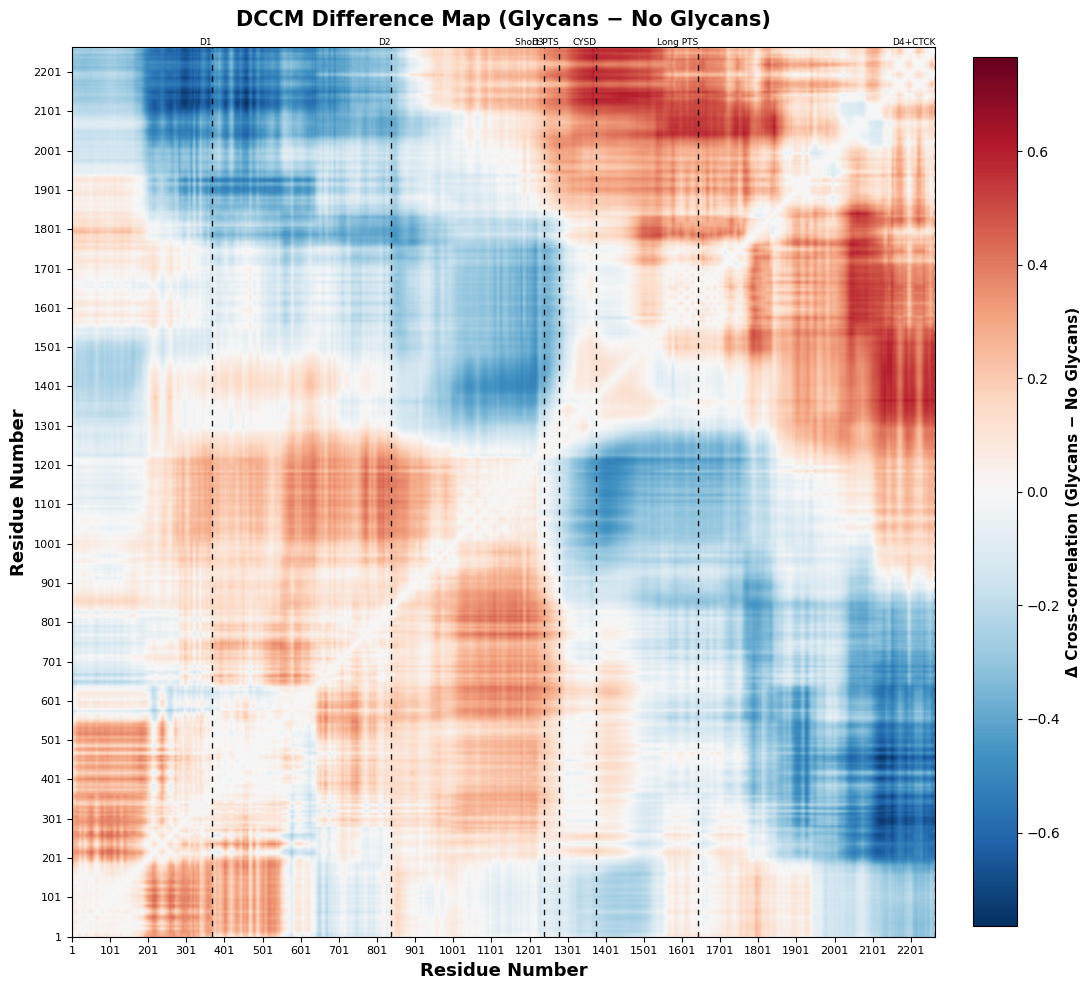

Saved: /home/computer2/analysis_simulations/analysis/pca_plots/dccm_difference_map.png


In [6]:
dccm_diff = dccm_gly - dccm_nog
vlim = np.abs(dccm_diff).max()

fig, ax = plt.subplots(figsize=(11, 10), dpi=100)
im = ax.imshow(dccm_diff, cmap="RdBu_r", vmin=-vlim, vmax=vlim,
               origin="lower", aspect="auto")
add_domain_lines(ax)
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Δ Cross-correlation (Glycans − No Glycans)", fontsize=11, fontweight="bold")
cbar.ax.tick_params(labelsize=10)
ax.set_xticks(ticks)
ax.set_xticklabels(tick_labels, rotation=0, fontsize=8)
ax.set_yticks(ticks)
ax.set_yticklabels(tick_labels, fontsize=8)
ax.set_xlabel("Residue Number", fontsize=13, fontweight="bold")
ax.set_ylabel("Residue Number", fontsize=13, fontweight="bold")
ax.set_title("DCCM Difference Map (Glycans − No Glycans)", fontsize=15, fontweight="bold", pad=15)
plt.tight_layout()
out = os.path.join(output_dir, "dccm_difference_map.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")